## Projeto académico — Wholesale Customers
Análise exploratória, classificação e segmentação de clientes grossistas. Os dados dos membros do grupo foram removidos desta versão pública.

# Projeto - Wholesale Customers

## 1. Compreensão inicial dos dados

O dataset contém informações sobre os valores anuais de compras de clientes de um distribuidor grossista.

Os clientes estão divididos em dois tipos:
- **Horeca** - Hotel/Restaurant/Café
- **Retail** - Retalho

Para cada cliente, são registados os montantes anuais de compras em seis categorias de produtos, a região e o canal de distribuição.

A variável classe utilizada neste projeto será **"Channel"**, que identifica se o cliente pertence ao canal **"Horeca"** ou **"Retail"**.

Nesta primeira etapa será realizada uma exploração inicial do dataset, com o objetivo de compreender a sua estrutura, dimensões, tipos de dados e principais características.

### Significado dos atributos

Cada registo representa um cliente de um distribuidor grossista.
Os seis atributos relativos às compras indicam os montantes anuais
gastos nas diferentes categorias de produtos.

| Atributo | Significado |
|---|---|
| Region | Região do cliente: Lisboa (Lisbon), Porto (Oporto) ou outras regiões (Other). |
| Fresh | Compras anuais de produtos frescos. |
| Milk | Compras anuais de produtos lácteos. |
| Grocery | Compras anuais de produtos de mercearia. |
| Frozen | Compras anuais de produtos congelados. |
| Detergents_Paper | Compras anuais de detergentes e produtos de papel. |
| Delicassen | Compras anuais de produtos de delicatessen. |
| Channel | Canal do cliente: Horeca (hotelaria e restauração) ou Retail (retalho). |

"Region" e "Channel" são variáveis categóricas nominais. Os restantes
seis atributos são quantitativos.

Importação das bibliotecas utilizadas no projeto.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn import tree
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay, classification_report
from sklearn.compose import ColumnTransformer

import warnings
warnings.filterwarnings('ignore')

Carregamento do dataset e visualização das primeiras linhas.

In [2]:
df = pd.read_csv('./input/Dataset_F_Wholesale.csv')
df.head()

,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Channel
0,Other,1420,10810.0,16267.0,1593,6766,1838.0,Retail
1,Oporto,29635,2335.0,8280.0,3046,371,117.0,Horeca
2,Lisbon,8475,1931.0,1883.0,5004,3593,987.0,Horeca
3,Lisbon,11092,5008.0,5249.0,453,392,373.0,Horeca
4,Other,17623,4280.0,7305.0,2279,960,2616.0,Horeca


Verificação do número de registos e atributos.

In [3]:
df.shape

(444, 8)

O dataset é constituído por 444 registos e 8 atributos.

Identificação dos atributos do dataset.

In [4]:
df.columns

Index(['Region', 'Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper',
       'Delicassen', 'Channel'],
      dtype='object')

Análise da estrutura e dos tipos de dados.

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 444 entries, 0 to 443
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Region            444 non-null    object 
 1   Fresh             444 non-null    int64  
 2   Milk              438 non-null    float64
 3   Grocery           438 non-null    float64
 4   Frozen            444 non-null    int64  
 5   Detergents_Paper  444 non-null    int64  
 6   Delicassen        438 non-null    float64
 7   Channel           444 non-null    object 
dtypes: float64(3), int64(3), object(2)
memory usage: 27.9+ KB


In [6]:
df.isna().sum()

Region              0
Fresh               0
Milk                6
Grocery             6
Frozen              0
Detergents_Paper    0
Delicassen          6
Channel             0
dtype: int64

A análise inicial mostra que o dataset possui atributos categóricos e numéricos.

Os atributos **Region** e **Channel** são categóricos, enquanto os restantes atributos representam valores anuais de compras.

Foram identificados valores omissos nos atributos **Milk**, **Grocery** e **Delicassen**, com 6 valores em falta em cada um deles. Os restantes atributos não apresentam valores omissos.

Antes de decidir como tratar estes valores, será analisada a localização dos registos que os contêm.

Quantos clientes são realmente afetados e como os valores omissos estão distribuídos?

In [7]:
df[df.isna().any(axis=1)]

,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Channel
30,Other,13146,1124.0,4523.0,1420,549,NaN,Retail
67,Oporto,7588,1897.0,NaN,417,2208,254.0,Retail
74,Other,3830,5291.0,NaN,317,6694,3182.0,Retail
181,Other,43265,5025.0,8117.0,6312,1579,NaN,Horeca
206,Other,68951,NaN,12609.0,8692,751,2406.0,Horeca
230,Other,22647,9776.0,13792.0,2915,4482,NaN,Retail
254,Other,12205,12697.0,NaN,869,12034,1009.0,Retail
262,Other,5924,584.0,542.0,4052,283,NaN,Horeca
270,Lisbon,11908,8053.0,NaN,1069,6374,698.0,Retail
272,Other,45640,NaN,6536.0,7368,1532,230.0,Horeca


### Análise descritiva inicial dos atributos numéricos

Antes de definir o tratamento dos valores omissos, serão analisadas as principais estatísticas descritivas dos atributos numéricos.

In [8]:
df.describe()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,444.000000,438.000000,438.000000,444.000000,444.000000,438.000000
mean,11943.468468,5756.607306,7895.753425,3049.957207,2885.743243,1486.125571
std,12609.311272,7371.451482,9450.206466,4838.342466,4751.993387,2750.379012
min,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,3127.750000,1541.250000,2155.500000,732.750000,256.750000,406.750000
50%,8413.500000,3611.500000,4755.500000,1498.000000,820.500000,965.500000
75%,16850.500000,7176.000000,10510.250000,3532.500000,3922.000000,1787.000000
max,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


Observa-se uma diferença considerável entre a média e a mediana em várias categorias de compras. 
Além disso, os valores máximos encontram-se bastante acima do terceiro quartil (75%), indicando uma possível assimetria na distribuição dos dados e a presença de valores extremos.

Nas variáveis que apresentam valores omissos (**Milk**, **Grocery** e **Delicassen**), a mediana apresenta-se como uma possível alternativa para o tratamento desses valores, por ser menos influenciada por valores extremos do que a média.

Mediana dessas três categorias para cada "Channel"

In [9]:
df.groupby('Channel')[['Milk', 'Grocery', 'Delicassen']].median()

,Milk,Grocery,Delicassen
Channel,,,
Horeca,2157.0,2765.5,823.0
Retail,7812.0,12271.5,1340.0


Podemos ver diferenças relevantes entre as medianas das categorias de compras dos clientes Horeca e Retail, principalmente em **Milk** e **Grocery**.

Por este motivo, optamos por tratar os valores omissos utilizando a **mediana da respetiva categoria de compras dentro de cada "Channel"**, em vez da mediana global do dataset.

A mediana foi escolhida por ser menos sensível a valores extremos e o agrupamento por "Channel" permite considerar as diferenças existentes nos padrões de compra entre os dois tipos de clientes.

## 2. Qualidade e preparação dos dados

Nesta secção será analisada a qualidade dos dados, considerando os valores omissos, os registos duplicados, os possíveis valores extremos e os tipos de dados. Serão também justificadas as decisões tomadas para preparar o dataset para a análise exploratória, a classificação e o clustering.

In [10]:
df[df['Milk'].isna()]

,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Channel
206,Other,68951,NaN,12609.0,8692,751,2406.0,Horeca
272,Other,45640,NaN,6536.0,7368,1532,230.0,Horeca
314,Lisbon,2362,NaN,11364.0,913,5957,791.0,Retail
351,Other,1406,NaN,28986.0,673,836,3.0,Retail
354,Other,18291,NaN,21042.0,5373,4173,14472.0,Horeca
395,Other,4591,NaN,16709.0,33,6956,433.0,Retail


In [11]:
def preencher_mediana(coluna):
    mediana_horeca = df.loc[df['Channel'] == 'Horeca', coluna].median()
    mediana_retail = df.loc[df['Channel'] == 'Retail', coluna].median()

    df.loc[(df[coluna].isna()) & (df['Channel'] == 'Horeca'), coluna] = mediana_horeca
    df.loc[(df[coluna].isna()) & (df['Channel'] == 'Retail'), coluna] = mediana_retail

In [12]:
colunas_na = ['Milk', 'Grocery', 'Delicassen']

for coluna in colunas_na:
    preencher_mediana(coluna)

In [13]:
df.isna().sum()

Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
Channel             0
dtype: int64

Os valores omissos identificados em **Milk**, **Grocery** e **Delicassen** foram preenchidos utilizando a mediana de cada atributo de acordo com o respetivo **Channel**.

Esta abordagem foi utilizada devido às diferenças observadas entre os padrões de compra dos clientes **Horeca** e **Retail** e por a mediana ser menos influenciada por possíveis valores extremos.

Após o tratamento, verificou-se que o dataset não apresenta valores omissos.

### Verificação de registos duplicados

Será verificada a existência de registos duplicados no dataset.

In [14]:
df.duplicated().sum()

np.int64(4)

In [15]:
df[df.duplicated(keep=False)]

,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Channel
79,Oporto,243,12939.0,8852.0,799,3909,211.0,Retail
101,Other,7780,2495.0,9464.0,669,2518,501.0,Horeca
205,Other,10290,1981.0,2232.0,1038,168,2125.0,Horeca
238,Other,7780,2495.0,9464.0,669,2518,501.0,Horeca
259,Other,10290,1981.0,2232.0,1038,168,2125.0,Horeca
316,Oporto,243,12939.0,8852.0,799,3909,211.0,Retail
406,Other,4456,5266.0,13227.0,25,6818,1393.0,Horeca
419,Other,4456,5266.0,13227.0,25,6818,1393.0,Horeca


In [16]:
df = df.drop_duplicates()

In [17]:
df.shape

(440, 8)

In [18]:
df.duplicated().sum()

np.int64(0)

### Resultado do tratamento dos registos duplicados

Foram identificados e removidos 4 registos duplicados, reduzindo o dataset de 444 para 440 observações.

Após a remoção, foi realizada uma nova verificação, confirmando a inexistência de registos totalmente duplicados.

Esta operação permite evitar que observações repetidas influenciem os resultados das análises posteriores.

### Estatísticas descritivas após o tratamento dos dados

Serão novamente calculadas as estatísticas descritivas dos atributos
numéricos, após o preenchimento dos valores omissos e a remoção
dos registos duplicados.

In [19]:
df.describe()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,12000.297727,5746.863636,7928.836364,3071.931818,2881.493182,1483.329545
std,12647.328865,7350.734654,9435.622586,4854.673333,4767.854448,2743.602405
min,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,3127.750000,1555.750000,2156.500000,742.250000,256.750000,410.500000
50%,8504.000000,3611.500000,4785.500000,1526.000000,816.500000,962.500000
75%,16933.750000,7217.500000,10725.500000,3554.250000,3922.000000,1781.000000
max,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


Após o tratamento, as seis categorias de compras apresentam
440 valores válidos.

A média é superior à mediana em todas as categorias, sugerindo
a influência de montantes de compras elevados. Os desvios padrão
indicam dispersão dos valores em torno das respetivas médias.

Os valores máximos encontram-se bastante acima do terceiro quartil,
pelo que será analisada a existência de possíveis valores extremos.

### Identificação de possíveis valores extremos

Após o tratamento dos valores omissos e dos registos duplicados, será analisada a existência de possíveis valores extremos nos atributos numéricos relativos às compras.

Para esta análise será utilizada a **Amplitude Interquartil (AIQ)**, calculada pela diferença entre o terceiro quartil (Q3) e o primeiro quartil (Q1).

Serão considerados possíveis valores extremos aqueles que se encontrem abaixo de **Q1 - 1,5 × AIQ** ou acima de **Q3 + 1,5 × AIQ**.

A identificação de um possível valor extremo não implica necessariamente a sua remoção, sendo necessária a análise dos resultados antes de tomar qualquer decisão.

In [20]:
q1 = df['Fresh'].quantile(0.25)
q3 = df['Fresh'].quantile(0.75)

aiq = q3 - q1

print('Q1:', q1)
print('Q3:', q3)
print('AIQ:', aiq)

Q1: 3127.75
Q3: 16933.75
AIQ: 13806.0


In [21]:
def identificar_outliers(coluna):
    q1 = df[coluna].quantile(0.25)
    q3 = df[coluna].quantile(0.75)

    aiq = q3 - q1

    limite_inferior = q1-(1.5*aiq)
    limite_superior = q3+(1.5*aiq)

    return df[(df[coluna] < limite_inferior) | (df[coluna] > limite_superior)]

In [22]:
identificar_outliers('Fresh')

,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Channel
21,Lisbon,47493,2567.0,3779.0,5243,828,2253.0,Horeca
35,Other,40721,3916.0,5876.0,532,2587,1278.0,Retail
83,Lisbon,53205,4959.0,7336.0,3012,967,818.0,Horeca
97,Other,39679,3944.0,4955.0,1364,523,2235.0,Retail
154,Other,56159,555.0,902.0,10002,212,2916.0,Horeca
156,Other,42786,286.0,471.0,1388,32,22.0,Horeca
169,Other,39228,1431.0,764.0,4510,93,2346.0,Horeca
179,Other,43088,2100.0,2609.0,1200,1107,823.0,Horeca
181,Other,43265,5025.0,8117.0,6312,1579,823.0,Horeca
189,Other,56082,3504.0,8906.0,18028,1480,2498.0,Horeca


Para o atributo **Fresh**, o método do AIQ identificou possíveis valores extremos acima do limite superior calculado.

Estes valores não serão removidos nesta fase, uma vez que podem representar clientes com volumes de compras elevados e não necessariamente erros nos dados. A decisão sobre o tratamento dos valores extremos será tomada após a análise dos restantes atributos.

A função será aplicada aos seis atributos relativos às compras, de forma a identificar a quantidade de possíveis valores extremos existente em cada categoria.

In [23]:
colunas_compras = df.columns[1:7]

for coluna in colunas_compras:
    outliers = identificar_outliers(coluna)
    print(coluna, ':', len(outliers))

Fresh : 20
Milk : 26
Grocery : 23
Frozen : 43
Detergents_Paper : 30
Delicassen : 25


Foram identificados possíveis valores extremos em todas as categorias de compras através do método do AIQ. O atributo **Frozen** apresentou a maior quantidade de possíveis outliers, com 43 registos, seguido de **Detergents_Paper**, com 30.

Apesar da existência destes valores extremos, optamos por não os remover, uma vez que podem representar clientes com volumes de compras elevados e não necessariamente erros nos dados. A sua remoção poderia resultar na perda de informação relevante sobre os diferentes padrões de compra dos clientes.

### Verificação dos tipos de dados e atributos

Após os tratamentos realizados, foram novamente analisados os tipos de dados e a relevância dos atributos presentes no dataset.

Os atributos **"Region"** e **"Channel"** são categóricos, enquanto os seis atributos relativos às compras são numéricos.

Não foram identificados atributos desnecessários nesta fase, uma vez que todos apresentam informação relevante para os objetivos da análise.

Também não foram realizadas transformações ou normalizações adicionais nesta etapa. A necessidade de normalização será avaliada posteriormente, de acordo com as técnicas utilizadas nas etapas seguintes do projeto.

In [24]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 440 entries, 0 to 443
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Region            440 non-null    object 
 1   Fresh             440 non-null    int64  
 2   Milk              440 non-null    float64
 3   Grocery           440 non-null    float64
 4   Frozen            440 non-null    int64  
 5   Detergents_Paper  440 non-null    int64  
 6   Delicassen        440 non-null    float64
 7   Channel           440 non-null    object 
dtypes: float64(3), int64(3), object(2)
memory usage: 30.9+ KB


## 3. Análise Exploratória dos Dados

Após a preparação dos dados, será realizada uma análise exploratória com o objetivo de compreender as principais características do dataset, identificar diferenças nos padrões de compra dos clientes e analisar possíveis relações entre os atributos.

Nesta etapa serão utilizadas estatísticas descritivas e visualizações adequadas aos objetivos da análise.

## Análise dos padrões de compra por "Channel"

Inicialmente serão analisados os valores das diferentes categorias de compras de acordo com o tipo de cliente, de forma a identificar possíveis diferenças entre os clientes Horeca e Retail.

In [25]:
df.groupby('Channel')[colunas_compras].median()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Channel,,,,,,
Horeca,9581.5,2157.0,2736.25,2057.5,385.5,823.0
Retail,5993.5,7812.0,12271.50,1081.0,5614.5,1340.0


In [26]:
df['Channel'].value_counts()

Channel
Horeca    298
Retail    142
Name: count, dtype: int64

O dataset apresenta **298 clientes Horeca** e **142 clientes Retail**, verificando-se uma maior representação de clientes do canal Horeca.

Devido à diferença no número de clientes entre os dois grupos, a comparação dos padrões de compra será realizada através de medidas descritivas, evitando comparar apenas os valores totais das compras.

In [27]:
df.groupby('Channel')[colunas_compras].mean()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Channel,,,,,,
Horeca,13475.560403,3431.040268,3968.518456,3748.251678,790.560403,1366.684564
Retail,8904.323944,10606.830986,16239.926056,1652.612676,7269.507042,1728.119718


A comparação entre média e mediana confirma diferenças nos padrões de compra entre os dois canais.

As medianas das compras são superiores em Fresh e Frozen para os clientes **Horeca**, e em Milk, Grocery, Detergents_Paper e Delicassen
para os clientes **Retail**.

Verifica-se também que, em todas as categorias e nos dois canais, a média é superior à mediana, o que é consistente com a influência
de clientes com montantes de compras elevados.

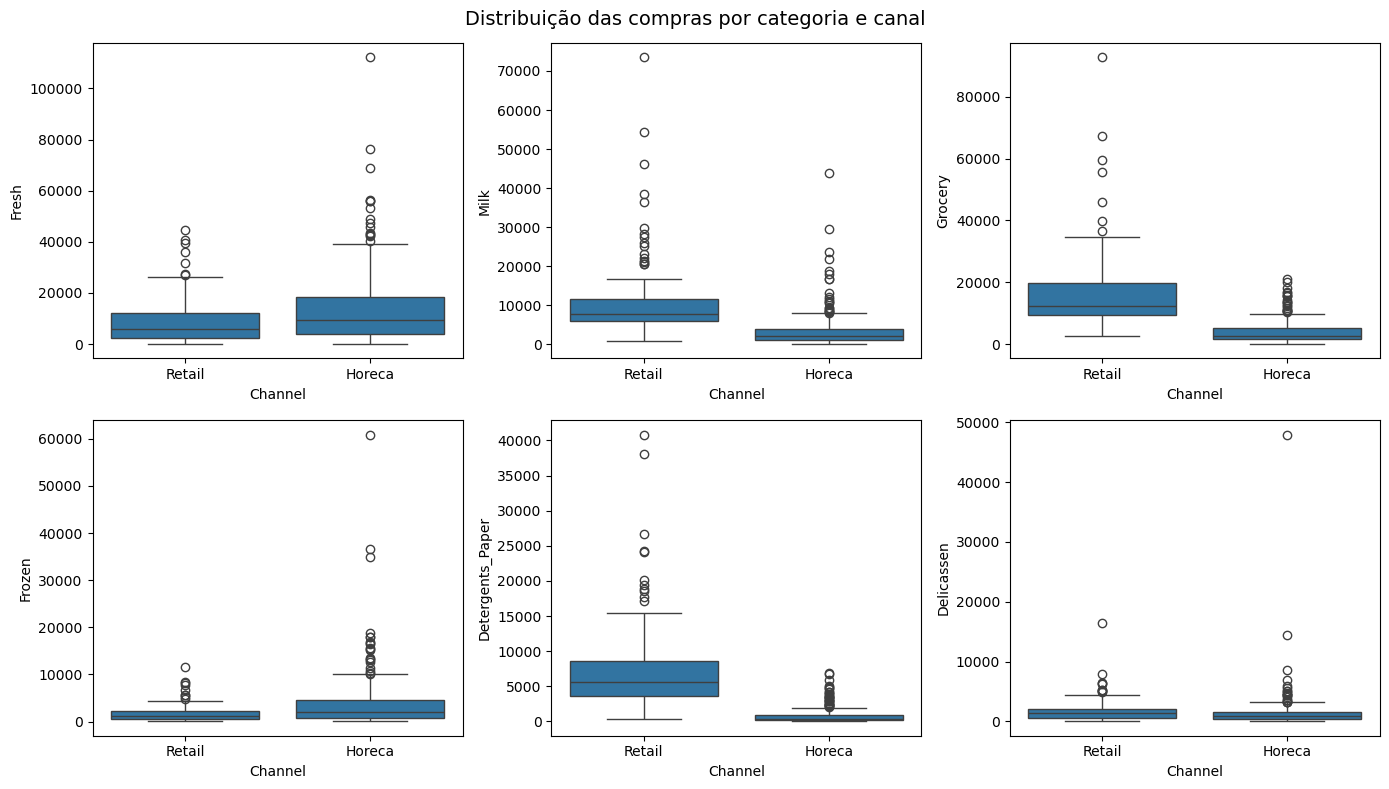

In [28]:
fig, axes = plt.subplots(2, 3, figsize=(14,8))

for i, coluna in enumerate(colunas_compras):
    linha = i // 3
    coluna_grafico = i % 3

    sns.boxplot(data=df, x='Channel', y=coluna, ax=axes[linha, coluna_grafico])

fig.suptitle('Distribuição das compras por categoria e canal', fontsize=14)
plt.tight_layout()
plt.show()

### Análise das compras por categoria e "Channel"

A análise dos boxplots evidencia diferenças nos padrões de compras
entre os clientes "Horeca" e "Retail".

Os clientes "Horeca" apresentam medianas superiores nas categorias
(Fresh e Frozen), enquanto os clientes "Retail" apresentam medianas
superiores em (Milk, Grocery, Detergents_Paper e Delicassen).

Observam-se ainda diferenças na dispersão dos valores e a presença
de possíveis outliers em todas as categorias, confirmando os
resultados identificados durante a preparação dos dados.

Estes resultados sugerem que o canal de distribuição está associado
a diferentes perfis de compras.

## Análise dos padrões de compra por "Region"

In [29]:
df['Region'].value_counts()

Region
Other     316
Lisbon     77
Oporto     47
Name: count, dtype: int64

### Distribuição dos clientes por região

A região "Other" reúne 316 clientes, enquanto "Lisbon" apresenta 77
e "Oporto" 47. Existe, portanto, uma distribuição desigual dos clientes
pelas três regiões.

Por este motivo, a comparação dos padrões de compras será baseada
nas médias e medianas, evitando comparar apenas os totais, que são
influenciados pelo número de clientes de cada região.

In [30]:
df.groupby('Region')[colunas_compras].median()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Region,,,,,,
Lisbon,7363.0,3748.0,3838.0,1801.0,737.0,806.0
Oporto,8090.0,2374.0,6360.0,1455.0,811.0,898.0
Other,8752.5,3664.0,4755.5,1498.0,856.0,994.0


### Análise das medianas por região

A comparação das medianas revela diferenças nos padrões de compras entre as três regiões.

A região "Other" apresenta as maiores medianas em (Fresh, Detergents_Paper e Delicassen). "Lisbon" destaca-se em (Milk e Frozen),
enquanto "Oporto" apresenta a maior mediana em (Grocery).

Para complementar esta análise, serão calculadas as médias por região e comparadas com as medianas, permitindo observar como os montantes elevados podem influenciar estas medidas.

In [31]:
df.groupby('Region')[colunas_compras].mean()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Region,,,,,,
Lisbon,11101.727273,5502.792208,7304.694805,3000.337662,2651.116883,1328.233766
Oporto,9887.680851,5088.170213,9368.329787,4045.361702,3687.468085,1159.702128
Other,12533.471519,5904.306962,7866.819620,2944.594937,2817.753165,1569.256329


### Análise das médias por região

A comparação entre as médias e as medianas revela que as médias são superiores às medianas nas seis categorias de compras e nas três regiões.

Este comportamento sugere a existência de distribuições assimétricas à direita, nas quais alguns clientes com valores de compras elevados influenciam as médias.

Observa-se também que a região com maior média nem sempre apresenta a maior mediana, como acontece na categoria Frozen.

Desta forma, a mediana constitui uma medida mais robusta para comparar os padrões típicos de compras entre regiões, por ser menos sensível aos valores extremos.

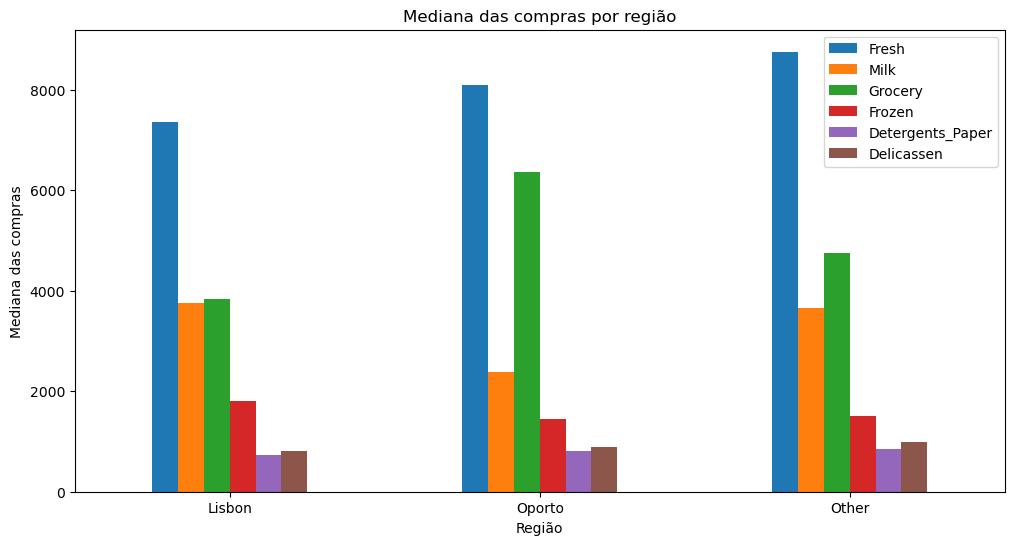

In [32]:
regiao_medianas = df.groupby('Region')[colunas_compras].median()

regiao_medianas.plot.bar(figsize=(12,6))
plt.title('Mediana das compras por região')
plt.xlabel('Região')
plt.ylabel('Mediana das compras')
plt.xticks(rotation=0)
plt.show()

### Interpretação do gráfico de compras por região

O gráfico permite visualizar as diferenças entre as medianas
das compras nas três regiões. Nenhuma região apresenta as maiores
medianas em todas as categorias.

As categorias apresentam diferentes ordens de grandeza, pelo que
a escala comum torna algumas diferenças menos evidentes. A leitura
do gráfico deve, por isso, ser complementada com a tabela das medianas.

## Relações entre as categorias de compras

Nesta análise serão estudadas as relações entre os montantes anuais
de compras nas seis categorias, utilizando a correlação de Pearson
e um gráfico de dispersão.

In [33]:
df[colunas_compras].corr()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Fresh,1.000000,0.097404,-0.011634,0.345881,-0.101953,0.217798
Milk,0.097404,1.000000,0.722497,0.125227,0.664633,0.421374
Grocery,-0.011634,0.722497,1.000000,-0.039458,0.920964,0.209475
Frozen,0.345881,0.125227,-0.039458,1.000000,-0.131525,0.388557
Detergents_Paper,-0.101953,0.664633,0.920964,-0.131525,1.000000,0.073157
Delicassen,0.217798,0.421374,0.209475,0.388557,0.073157,1.000000


### Interpretação da matriz de correlação geral

A matriz de correlação de Pearson permite analisar as relações lineares entre as seis categorias de compras, considerando todos os clientes do dataset.

Observa-se uma **correlação positiva muito forte entre Grocery e Detergents_Paper (0,921)**, indicando que clientes com compras mais elevadas numa destas categorias tendem também a apresentar valores superiores na outra.

Verificam-se ainda correlações positivas entre **Milk e Grocery (0,722)** e entre **Milk e Detergents_Paper (0,665)**.

Por outro lado, **Fresh e Grocery apresentam uma correlação praticamente nula (-0,012)**, indicando ausência de uma relação linear relevante entre estas categorias no conjunto dos clientes.

Estes resultados permitem identificar associações entre as categorias de compras. No entanto, como o dataset contém clientes de dois canais de distribuição distintos, torna-se relevante analisar se estas relações se mantêm quando consideramos cada canal separadamente.

In [34]:
df.groupby('Channel')[colunas_compras].corr()

Fresh      Milk   Grocery    Frozen  \
Channel                                                            
Horeca  Fresh             1.000000  0.231405  0.234777  0.335765   
        Milk              0.231405  1.000000  0.599166  0.405638   
        Grocery           0.234777  0.599166  1.000000  0.258149   
        Frozen            0.335765  0.405638  0.258149  1.000000   
        Detergents_Paper -0.007456  0.249907  0.547610 -0.031201   
        Delicassen        0.226750  0.645327  0.441956  0.428240   
Retail  Fresh             1.000000  0.244877  0.088819  0.268481   
        Milk              0.244877  1.000000  0.651102  0.183160   
        Grocery           0.088819  0.651102  1.000000  0.047336   
        Frozen            0.268481  0.183160  0.047336  1.000000   
        Detergents_Paper  0.022986  0.630041  0.917799  0.016837   
        Delicassen        0.259203  0.357681  0.161970  0.309626   

                          Detergents_Paper  Delicassen  
Channel                                                 
Horeca  Fresh                    -0.007456    0.226750  
        Milk                      0.249907    0.645327  
        Grocery                   0.547610    0.441956  
        Frozen                   -0.031201    0.428240  
        Detergents_Paper          1.000000    0.069627  
        Delicassen                0.069627    1.000000  
Retail  Fresh                     0.022986    0.259203  
        Milk                      0.630041    0.357681  
        Grocery                   0.917799    0.161970  
        Frozen                    0.016837    0.309626  
        Detergents_Paper          1.000000    0.073421  
        Delicassen                0.073421    1.000000

### Interpretação da matriz de correlação por canal

A análise da correlação de Pearson por canal de distribuição permite verificar se as relações entre as categorias de compras apresentam diferenças entre os clientes **Horeca e Retail**.

A principal diferença observa-se entre **Grocery e Detergents_Paper**, cuja correlação é muito forte em **Retail (0,918)**, mas moderada em **Horeca (0,548)**.

Entre **Milk e Grocery**, verificam-se correlações positivas em ambos os canais, sendo ligeiramente superiores em **Retail (0,651)** relativamente a **Horeca (0,600)**.

Por outro lado, **Milk e Delicassen** apresentam uma correlação positiva mais elevada em **Horeca (0,645)** do que em **Retail (0,358)**, sugerindo diferenças nas associações entre estas categorias.

Relativamente a **Fresh e Grocery**, observa-se uma correlação positiva de pequena magnitude em **Horeca (0,235)** e praticamente nula em **Retail (0,089)**. Em ambos os canais, a relação linear é pouco expressiva.

Em conjunto, os resultados sugerem que as relações entre determinadas categorias de compras variam consoante o canal de distribuição. Assim, a análise por **Channel** complementa a correlação geral e contribui para uma melhor caracterização dos padrões de compras dos clientes.

Importa salientar que a correlação de Pearson mede associações lineares, não permitindo estabelecer relações de causa e efeito. Além disso, os valores extremos identificados anteriormente podem influenciar os coeficientes obtidos.

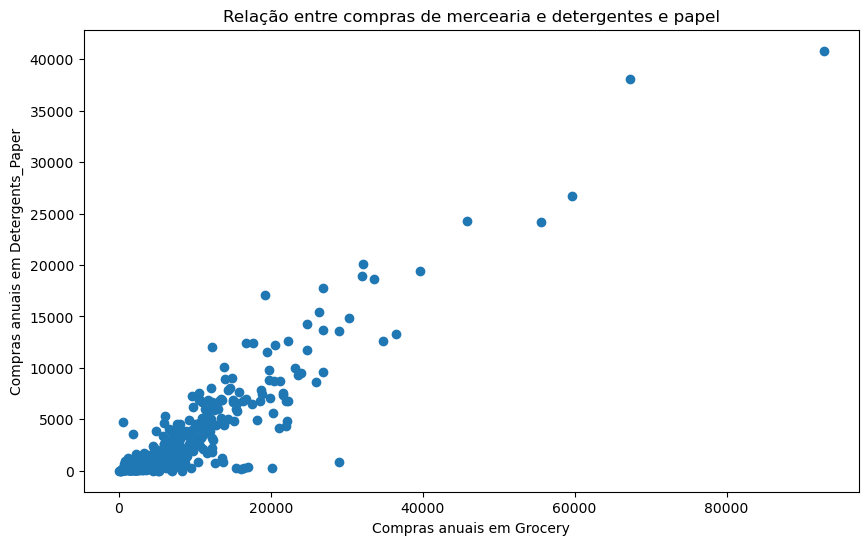

In [35]:
plt.figure(figsize=(10, 6))
plt.scatter(x=df['Grocery'], y=df['Detergents_Paper'])
plt.title('Relação entre compras de mercearia e detergentes e papel')
plt.xlabel('Compras anuais em Grocery')
plt.ylabel('Compras anuais em Detergents_Paper')
plt.xticks(rotation=0)
plt.show()

### Interpretação do gráfico de dispersão

Os pontos apresentam uma tendência crescente, consistente com a correlação positiva muito forte entre (Grocery e Detergents_Paper).

Observa-se uma concentração de clientes com compras relativamente baixas nas duas categorias e poucos clientes com montantes elevados.
Alguns pontos afastam-se da tendência geral, mostrando que a relação não é perfeita.

## Distribuição dos montantes de compras

Será utilizado um histograma de Grocery para analisar como se
distribuem os montantes de compras dos clientes.

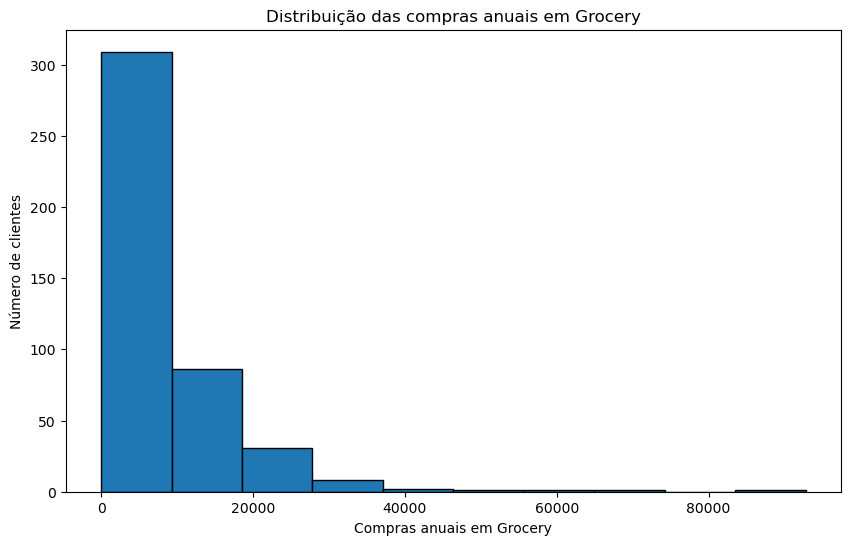

In [36]:
plt.figure(figsize=(10, 6))
plt.hist(df['Grocery'], bins=10, edgecolor='black')
plt.title('Distribuição das compras anuais em Grocery')
plt.xlabel('Compras anuais em Grocery')
plt.ylabel('Número de clientes')
plt.show()

### Interpretação da distribuição das compras em Grocery

A distribuição apresenta assimetria à direita: a maioria dos clientes concentra-se nos intervalos de compras mais baixos, enquanto a cauda
se prolonga em direção aos montantes elevados.

Este padrão é consistente com a média superior à mediana observada em (Grocery), uma vez que os valores elevados influenciam mais a média.

### Comparação das medidas de tendência central

Para complementar a análise, será utilizada uma função própria
que calcula a média e a mediana de uma categoria de compras.

A função será aplicada às seis categorias através de um ciclo for,
permitindo comparar as duas medidas em cada categoria.

In [37]:
def resumo_compras(coluna):
    media = df[coluna].mean()
    mediana = df[coluna].median()
    return media, mediana

In [38]:
for coluna in colunas_compras:
    media, mediana = resumo_compras(coluna)
    print(coluna, '- Média:', media, ' - Mediana:', mediana)

Fresh - Média: 12000.297727272728  - Mediana: 8504.0
Milk - Média: 5746.863636363636  - Mediana: 3611.5
Grocery - Média: 7928.836363636364  - Mediana: 4785.5
Frozen - Média: 3071.931818181818  - Mediana: 1526.0
Detergents_Paper - Média: 2881.4931818181817  - Mediana: 816.5
Delicassen - Média: 1483.3295454545455  - Mediana: 962.5


### Comparação entre a média e a mediana das compras

A função resumo_compras permite calcular a média e a mediana de cada
categoria, sendo aplicada às seis categorias através de um ciclo for.

Em todas as categorias, a média é superior à mediana. Este resultado
é consistente com a influência de montantes de compras elevados,
que afetam mais a média do que a mediana.

A mediana permite, assim, complementar a média na caracterização
dos valores de compras dos clientes.

## 4. Classificação — Decision Tree

Nesta etapa será desenvolvido um modelo de classificação para prever o canal de cada cliente, distinguindo entre Horeca e Retail.

A variável classe é Channel. Como atributos previsores, serão utilizadas a região e as seis categorias de compras: **Fresh, Milk, Grocery, Frozen, Detergents_Paper e Delicassen**.

A análise permitirá avaliar o desempenho da árvore de decisão e identificar os atributos que mais contribuem para distinguir os dois canais.

In [39]:
X = df.iloc[:, :-1].values
y = df.iloc[:, -1].values

In [40]:
X

array([['Other', 1420, 10810.0, ..., 1593, 6766, 1838.0],
       ['Oporto', 29635, 2335.0, ..., 3046, 371, 117.0],
       ['Lisbon', 8475, 1931.0, ..., 5004, 3593, 987.0],
       ...,
       ['Lisbon', 15603, 2703.0, ..., 4260, 325, 2563.0],
       ['Other', 27329, 1449.0, ..., 2436, 204, 1333.0],
       ['Lisbon', 8635, 820.0, ..., 2312, 415, 225.0]],
      shape=(440, 7), dtype=object)

### Codificação da variável Region

Region é uma variável categórica nominal, cujas categorias não possuem uma ordem natural.

Será utilizado o OneHotEncoder para representar cada região através de três colunas binárias: Lisbon, Oporto e Other.
Em cada registo, a coluna correspondente à região do cliente assume o valor 1 e as restantes assumem o valor 0.

Esta codificação permite incluir a região no modelo sem atribuir uma ordem numérica às suas categorias. As seis categorias de compras serão mantidas através do parâmetro remainder='passthrough'.

In [41]:
ct = ColumnTransformer(transformers=[('encoder', OneHotEncoder(), [0])], remainder='passthrough')
X = np.array(ct.fit_transform(X))

In [42]:
X

array([[0.0, 0.0, 1.0, ..., 1593, 6766, 1838.0],
       [0.0, 1.0, 0.0, ..., 3046, 371, 117.0],
       [1.0, 0.0, 0.0, ..., 5004, 3593, 987.0],
       ...,
       [1.0, 0.0, 0.0, ..., 4260, 325, 2563.0],
       [0.0, 0.0, 1.0, ..., 2436, 204, 1333.0],
       [1.0, 0.0, 0.0, ..., 2312, 415, 225.0]],
      shape=(440, 9), dtype=object)

Divisão dos dados em treino e teste

Os dados serão divididos em conjuntos de treino e teste. O conjunto de treino será utilizado para construir a árvore de decisão, enquanto o conjunto de teste permitirá avaliar o desempenho do modelo em observações que não foram utilizadas durante o treino.

Nesta análise, 75% dos dados serão utilizados para treino e 25% para teste.

In [43]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 0)

In [44]:
print('X_train: ', X_train.shape)
print('y_train: ', y_train.shape)
print('X_test: ', X_test.shape)
print('y_test: ', y_test.shape)

X_train:  (330, 9)
y_train:  (330,)
X_test:  (110, 9)
y_test:  (110,)


### Padronização dos atributos previsores

Será utilizado o StandardScaler para padronizar os atributos previsores, centrando os valores na média e ajustando a sua escala
pelo desvio padrão.

O método fit_transform calcula os parâmetros a partir do conjunto de treino e transforma os seus valores. No conjunto de teste,
transform aplica os mesmos parâmetros, sem os voltar a calcular.

Embora a árvore de decisão não necessite desta padronização, mantém-se esta etapa seguindo a sequência de preparação utilizada
nas aulas. Por esse motivo, os limites apresentados na árvore correspondem a valores padronizados, e não aos montantes originais
de compras.

In [45]:
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [46]:
X_test[0]

array([-0.45208358, -0.36074504,  0.63111416, -0.58072545,  2.07932261,
        1.3385639 , -0.29951535,  0.85836231,  1.17647295])

Criar a arvore de decisão

In [47]:
classifier = DecisionTreeClassifier(criterion = 'entropy', random_state = 0)
classifier.fit(X_train, y_train)

,criterion,'entropy'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


Avaliação do modelo: matriz de confusão e accuracy

A matriz de confusão permite comparar os canais reais com os canais previstos pelo modelo, identificando as classificações corretas e os erros cometidos.

A accuracy representa a proporção de clientes do conjunto de teste que foram corretamente classificados. A análise conjunta destas medidas permite avaliar a capacidade da árvore de decisão para distinguir os clientes Horeca e Retail.

Accuracy
0.8454545454545455


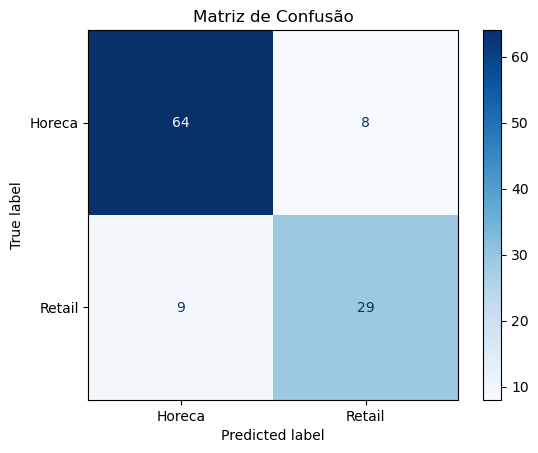

In [48]:
y_pred = classifier.predict(X_test)
cm = confusion_matrix(y_test, y_pred)

print("Accuracy")
print(accuracy_score(y_test, y_pred))

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classifier.classes_)

disp.plot(cmap='Blues')
plt.title("Matriz de Confusão")
plt.show()

### Interpretação da matriz de confusão e da accuracy

A árvore de decisão classificou corretamente 93 dos 110 clientes do conjunto de teste, correspondendo a uma accuracy de aproximadamente 84,55%.

Dos 72 clientes Horeca, 64 foram corretamente classificados e 8 foram classificados como Retail. Dos 38 clientes Retail, 29 foram corretamente classificados e 9 foram classificados como Horeca.

O modelo identificou uma proporção superior de clientes Horeca do que de clientes Retail. Estes resultados referem-se à divisão entre treino e teste utilizada e devem ser interpretados tendo em conta as limitações da preparação dos dados.

Interpretação das métricas de classificação

O classification_report apresenta as métricas precision, recall e F1-score para cada canal. A precision indica a proporção de previsões de uma classe que estão corretas; o recall indica a proporção de clientes dessa classe que foram corretamente identificados; e o F1-score combina estas duas medidas.

A comparação das métricas permite avaliar se o modelo apresenta um desempenho semelhante nos dois canais ou se revela maior dificuldade em identificar um deles.

In [49]:
print(classification_report(y_test.tolist(), y_pred.tolist()))

              precision    recall  f1-score   support

      Horeca       0.88      0.89      0.88        72
      Retail       0.78      0.76      0.77        38

    accuracy                           0.85       110
   macro avg       0.83      0.83      0.83       110
weighted avg       0.84      0.85      0.84       110



### Análise dos resultados por canal

O modelo apresenta melhor desempenho na identificação dos clientes Horeca, com precision de 0,88, recall de 0,89 e F1-score de 0,88.

Para Retail, a precision é de 0,78, o recall de 0,76 e o F1-score de 0,77. O recall indica que aproximadamente 76% dos clientes Retail do conjunto de teste foram corretamente identificados.

A diferença entre os F1-scores mostra que o desempenho não é igual nos dois canais, existindo maior dificuldade na classificação dos clientes Retail.

In [50]:
classes = np.unique(df.iloc[:, -1].values)
class_1 = ['Lisbon', 'Oporto', 'Other','Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']

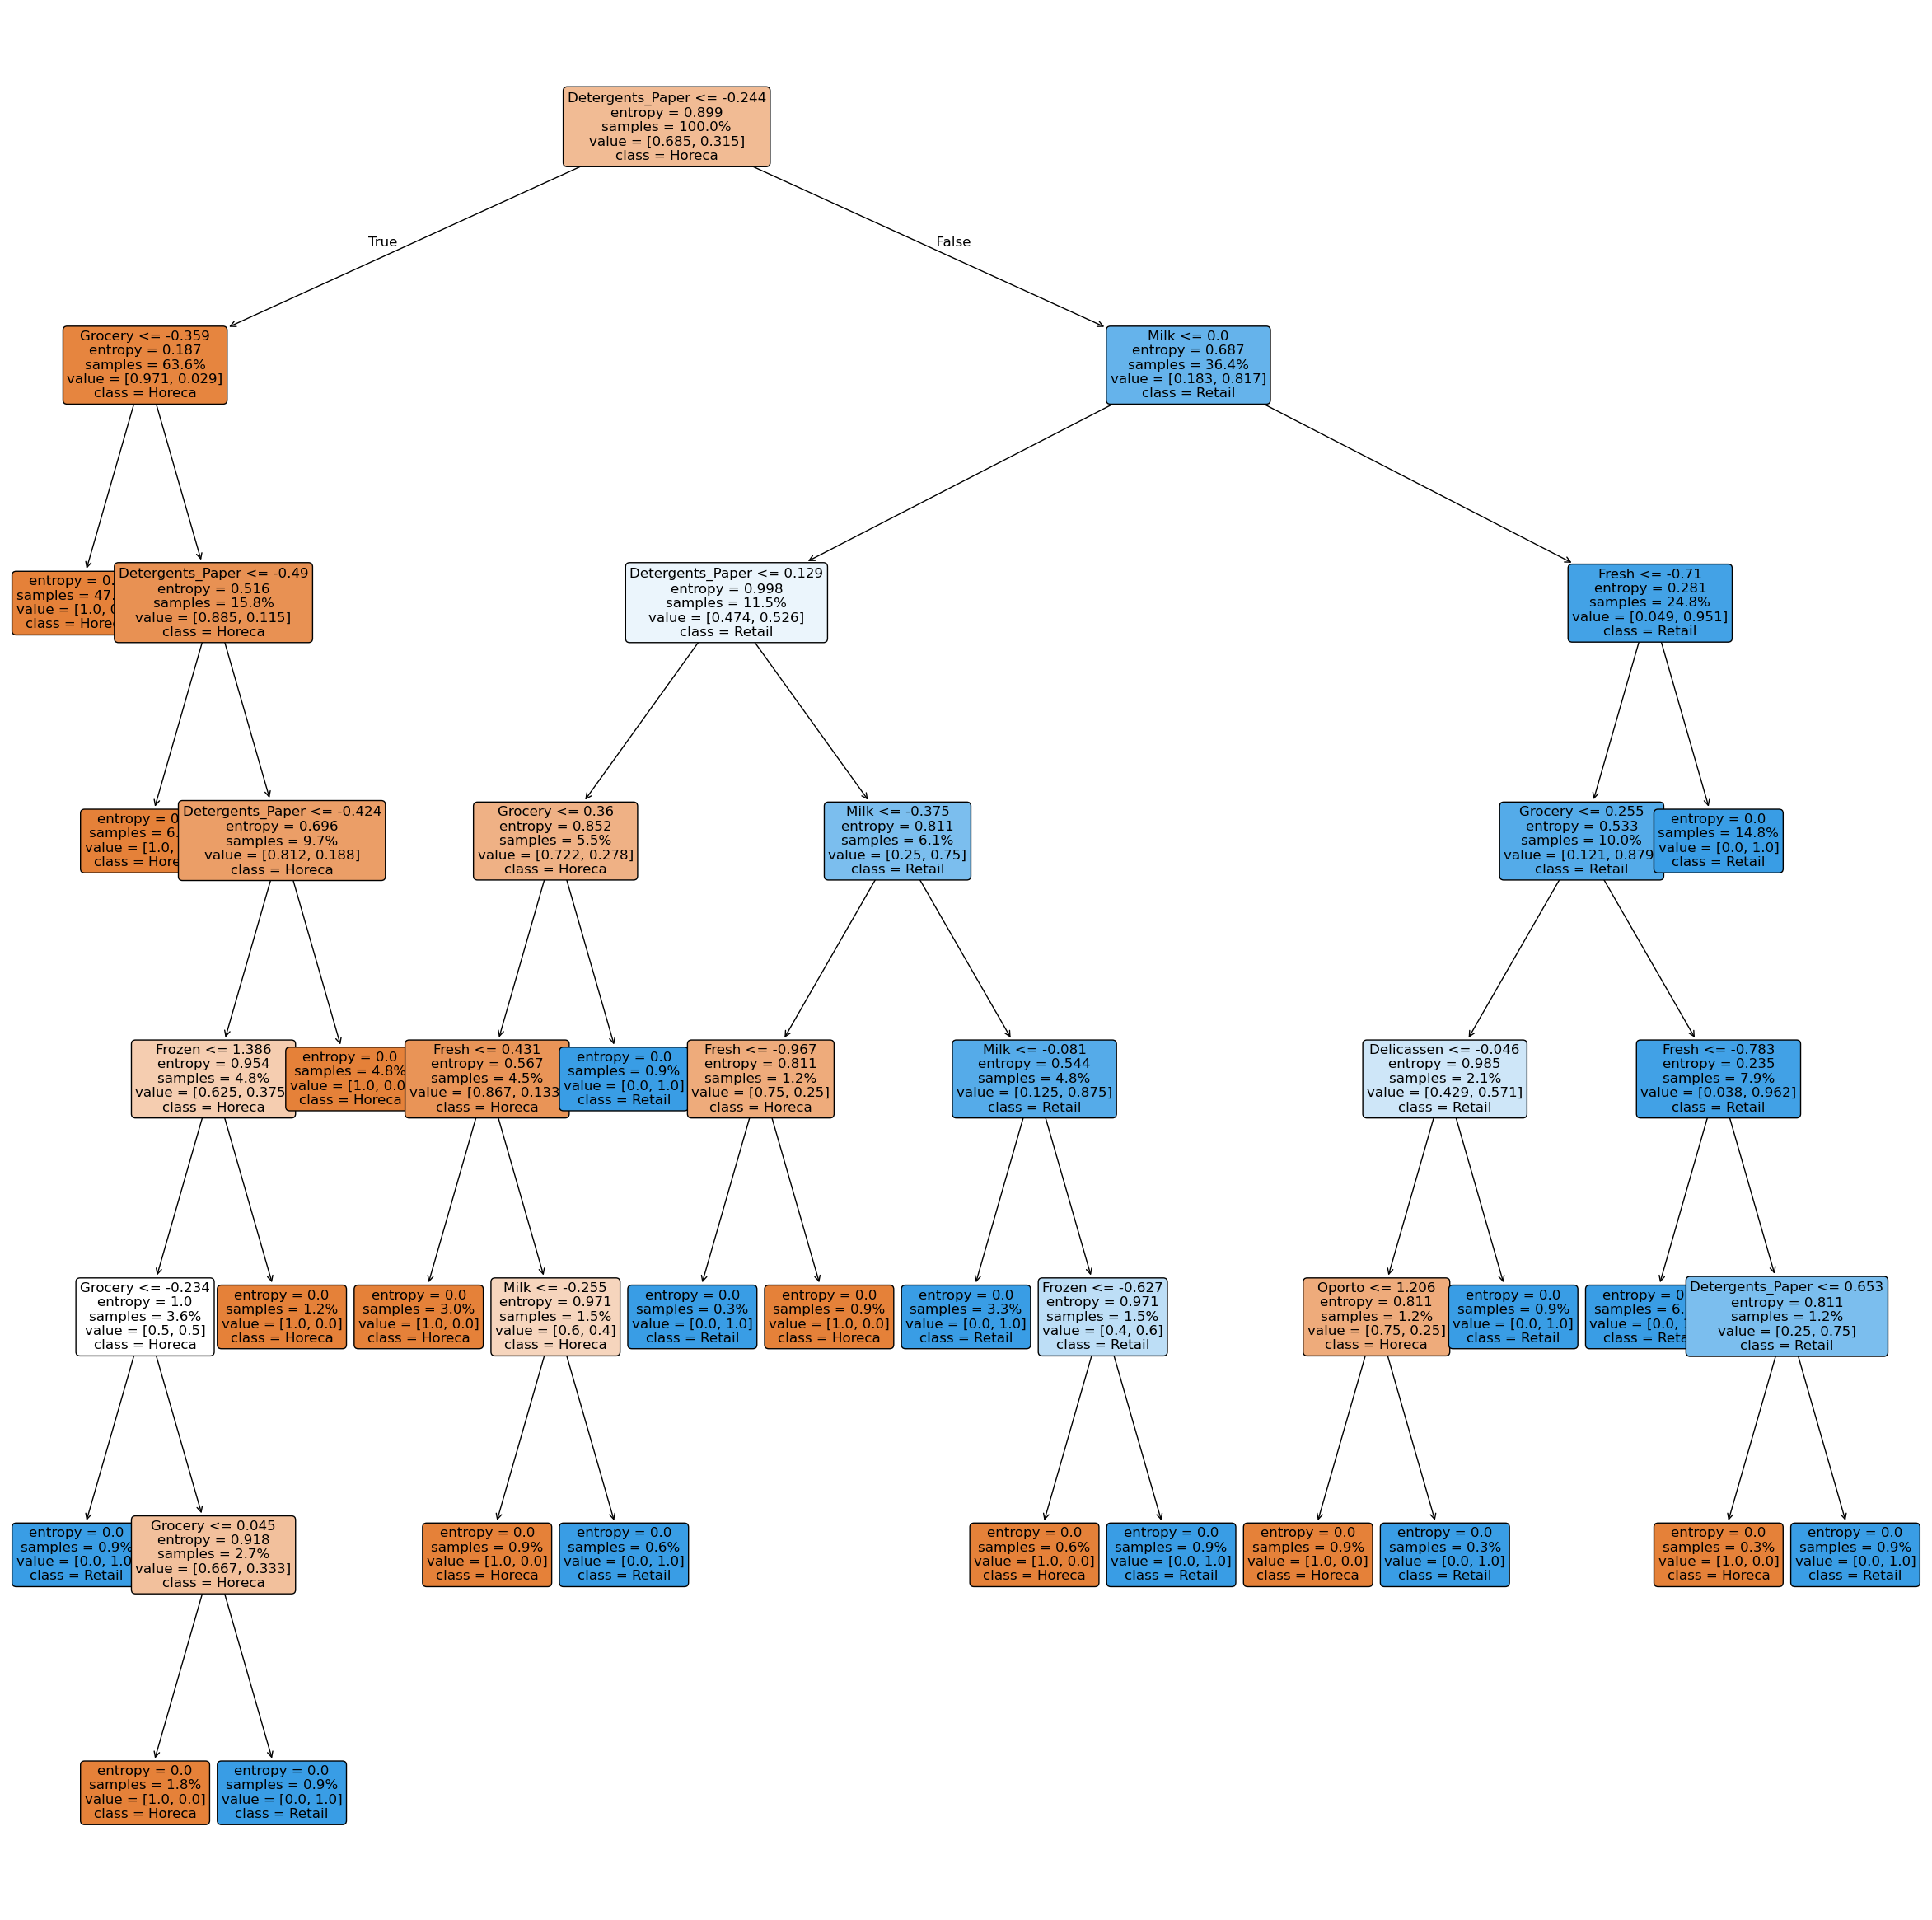

In [51]:
figura, eixos = plt.subplots(nrows=1, ncols=1, figsize=(30, 30))

tree.plot_tree(
    classifier,
    feature_names=class_1,
    class_names=classes,         
    filled=True,                 
    rounded=True,                
    proportion=True,             
    fontsize=12                  
)

plt.show()

In [52]:
regras = export_text(classifier, feature_names=class_1)
print(regras)

|--- Detergents_Paper <= -0.24
|   |--- Grocery <= -0.36
|   |   |--- class: Horeca
|   |--- Grocery >  -0.36
|   |   |--- Detergents_Paper <= -0.49
|   |   |   |--- class: Horeca
|   |   |--- Detergents_Paper >  -0.49
|   |   |   |--- Detergents_Paper <= -0.42
|   |   |   |   |--- Frozen <= 1.39
|   |   |   |   |   |--- Grocery <= -0.23
|   |   |   |   |   |   |--- class: Retail
|   |   |   |   |   |--- Grocery >  -0.23
|   |   |   |   |   |   |--- Grocery <= 0.05
|   |   |   |   |   |   |   |--- class: Horeca
|   |   |   |   |   |   |--- Grocery >  0.05
|   |   |   |   |   |   |   |--- class: Retail
|   |   |   |   |--- Frozen >  1.39
|   |   |   |   |   |--- class: Horeca
|   |   |   |--- Detergents_Paper >  -0.42
|   |   |   |   |--- class: Horeca
|--- Detergents_Paper >  -0.24
|   |--- Milk <= 0.00
|   |   |--- Detergents_Paper <= 0.13
|   |   |   |--- Grocery <= 0.36
|   |   |   |   |--- Fresh <= 0.43
|   |   |   |   |   |--- class: Horeca
|   |   |   |   |--- Fresh >  0.43
|   |

### Interpretação da árvore de decisão

A primeira divisão da árvore utiliza Detergents_Paper, mostrando que este atributo tem um papel importante na separação inicial dos clientes Horeca e Retail.

Nos níveis seguintes, são utilizados atributos como Grocery, Milk e Fresh. A região Oporto também surge numa das divisões, pelo que as regras não dependem exclusivamente das compras.

Os limites apresentados correspondem a valores padronizados. Por exemplo, um limite negativo indica um valor inferior à média do respetivo atributo no conjunto de treino, e não um montante de compras negativo.

Cada percurso desde a raiz até a uma folha representa uma sequência de condições que conduz à classificação de um cliente. Estas regras
descrevem o comportamento do modelo e não garantem que todos os clientes sejam classificados corretamente.

### Importância das categorias de compras

A importância dos atributos permite identificar quais as categorias de compras que mais contribuíram para as divisões realizadas pela árvore de decisão.

As categorias com maior importância são particularmente relevantes para distinguir Horeca e Retail neste modelo, enquanto as categorias com menor importância tiveram uma contribuição inferior para as divisões realizadas.


In [53]:
feature_importances = classifier.feature_importances_

for feature, importance in zip(class_1, feature_importances):
    print(f"Feature: {feature}, Importance: {importance}")

Feature: Lisbon, Importance: 0.0
Feature: Oporto, Importance: 0.010938084157369275
Feature: Other, Importance: 0.0
Feature: Fresh, Importance: 0.05134233466288833
Feature: Milk, Importance: 0.11620708602361737
Feature: Grocery, Importance: 0.12099008260402769
Feature: Frozen, Importance: 0.027388744732627115
Feature: Detergents_Paper, Importance: 0.6608258528243921
Feature: Delicassen, Importance: 0.012307814995078208


### Interpretação da importância dos atributos

Detergents_Paper apresenta a maior importância no modelo, com aproximadamente 66,1% da importância total das divisões. Seguem-se Grocery, com 12,1%, e Milk, com 11,6%.

Estes resultados indicam que as compras nestas três categorias foram as que mais contribuíram para distinguir os clientes Horeca e Retail na árvore construída.

Fresh apresenta uma importância de 5,1%, Frozen de 2,7% e Delicassen de 1,2%. Entre as regiões, apenas Oporto contribuiu para as divisões, com aproximadamente 1,1%.

Estas importâncias descrevem a utilização dos atributos neste modelo. Não representam relações de causa e efeito nem significam que os atributos com importância nula sejam irrelevantes noutros modelos.

### Limitação da avaliação da classificação

O projeto foi desenvolvido progressivamente, acompanhando os
conteúdos das aulas. O preenchimento dos valores omissos foi
realizado antes da divisão entre treino e teste, utilizando
as medianas de cada categoria de compras por Channel.

Esta preparação utiliza informação da variável que se pretende
prever e calcula as medianas com dados que posteriormente pertencem
também ao conjunto de teste. Por esse motivo, as métricas obtidas
podem apresentar uma avaliação otimista do desempenho do modelo.

Numa avaliação futura, o preenchimento deverá utilizar parâmetros
calculados apenas no conjunto de treino, sem recorrer ao Channel
dos clientes que se pretende classificar.

Definir valores binarios para a variavel Channel (0 = Horeca e 1 = Retail)

In [54]:
df['Channel'] = df['Channel'].map({'Horeca': 0, 'Retail': 1})
df['Region'] = df['Region'].map({'Lisbon' : 0, 'Oporto': 1, 'Other': 2})
df.head()

,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Channel
0,2,1420,10810.0,16267.0,1593,6766,1838.0,1
1,1,29635,2335.0,8280.0,3046,371,117.0,0
2,0,8475,1931.0,1883.0,5004,3593,987.0,0
3,0,11092,5008.0,5249.0,453,392,373.0,0
4,2,17623,4280.0,7305.0,2279,960,2616.0,0


In [55]:
todas_colunas = df.columns

## 5. Clustering

O objetivo desta etapa é identificar grupos de clientes com características semelhantes, utilizando o algoritmo K-Means.

Na formação dos grupos serão consideradas as seis categorias de compras e a variável Region. A inclusão da região segue a orientação do professor, que corrigiu este ponto do enunciado.

A variável Channel não será incluída nos atributos utilizados pelo K-Means. Após a formação dos clusters, serão analisadas as suas características de compras e a composição por canal e região.

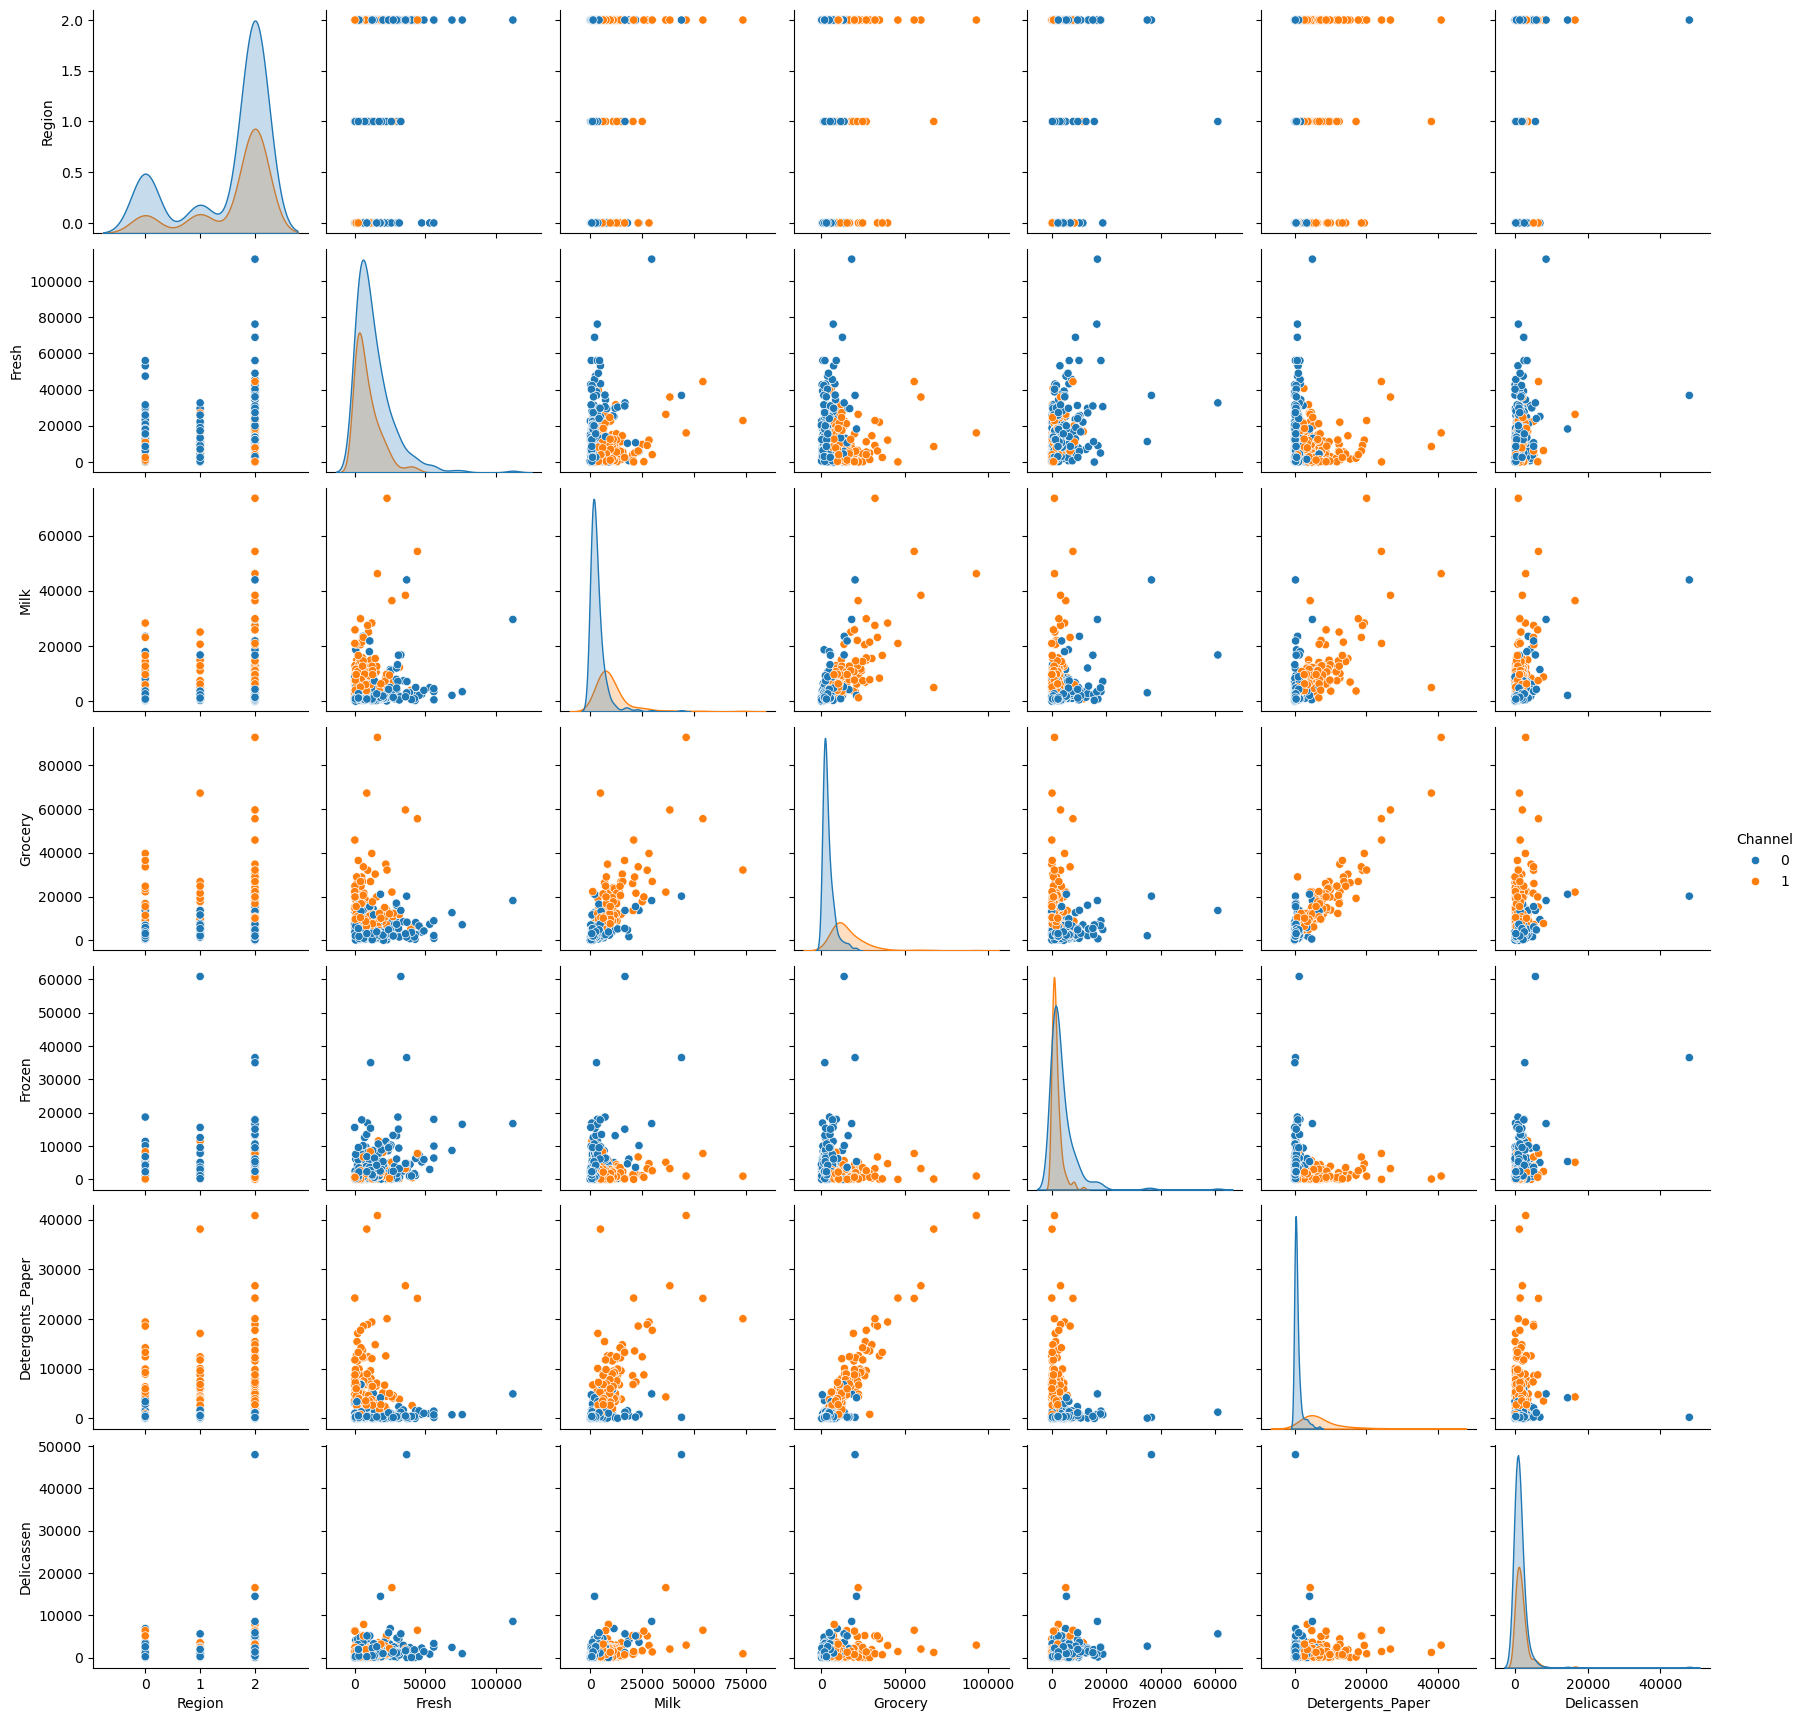

In [56]:
sns.pairplot(df[todas_colunas], hue='Channel')

### Interpretação do pairplot

O pairplot permite observar as relações entre os atributos e comparar visualmente os clientes Horeca e Retail.

Destaca-se a tendência crescente entre Grocery e Detergents_Paper, consistente com a correlação anteriormente calculada. Observa-se
também sobreposição entre os canais, indicando que os padrões de compras não permitem uma separação perfeita dos clientes.

Os valores de Region representam categorias codificadas, pelo que não devem ser interpretados como uma escala quantitativa.

### Seleção e representação dos atributos

Serão utilizadas a variável Region e as seis categorias de compras. Channel será excluído da formação dos clusters.

Nesta implementação, Region está codificada como Lisbon = 0, Oporto = 1 e Other = 2. As categorias de compras mantêm os seus
montantes originais, sem padronização.

Esta preparação constitui uma limitação: os códigos numéricos atribuem distâncias artificiais entre regiões, que não possuem uma ordem natural. Além disso, as categorias de compras com maior dispersão podem ter maior influência nas distâncias utilizadas pelo K-Means.

Os grupos obtidos devem, por isso, ser interpretados tendo em conta esta representação dos dados.

In [57]:
X_km = df.iloc[:, :-1]

Escolha do número de clusters — Método Elbow

O método Elbow permite analisar a variação da soma dos quadrados das distâncias aos centros dos clusters (WCSS) para diferentes números de grupos.

À medida que aumenta o número de clusters, a WCSS tende a diminuir. A escolha do número de grupos será apoiada pela observação do ponto a partir do qual essa redução se torna menos acentuada, procurando um equilíbrio entre a compactação dos grupos e a facilidade de interpretar os resultados.

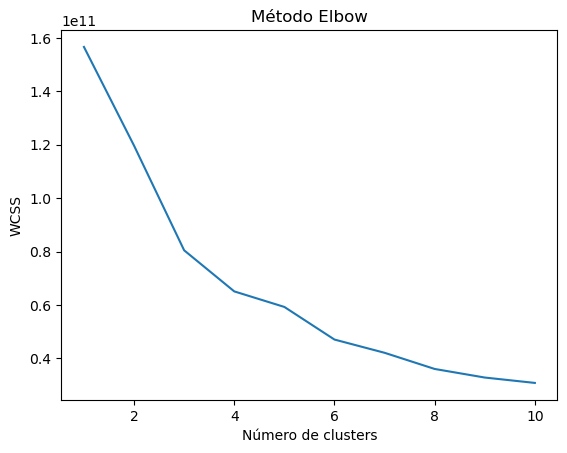

In [58]:
wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters = i, init = 'k-means++', random_state = 0)
    kmeans.fit(X_km)
    wcss.append(kmeans.inertia_)
    
plt.plot(range(1, 11), wcss)
plt.title('Método Elbow')
plt.xlabel('Número de clusters')
plt.ylabel('WCSS')
plt.show()

### Escolha do número de clusters

O gráfico Elbow apresenta uma redução acentuada da WCSS até cerca de três clusters. Observa-se também uma redução entre cinco e seis
clusters, após a qual as melhorias se tornam, em geral, menores.

Optou-se por seis clusters para explorar uma segmentação mais detalhada dos clientes. Esta escolha não constitui uma solução única ou necessariamente ótima, sendo necessário avaliar se os grupos obtidos apresentam características interpretáveis.

A solução será analisada considerando os perfis de compras e o número de clientes de cada grupo, com especial atenção aos clusters de menor dimensão.

In [59]:
kmeans = KMeans(n_clusters = 6, init = 'k-means++', random_state = 0)
y_kmeans = kmeans.fit_predict(X_km)

Caracterização dos clusters

In [60]:
df['Clusters'] = kmeans.labels_
df['Clusters'].value_counts()

Clusters
5    223
0    103
1     82
2     22
3      7
4      3
Name: count, dtype: int64

### Distribuição dos clientes pelos clusters

Os seis clusters apresentam dimensões diferentes. O cluster 5 é o mais numeroso, com 223 clientes, seguido do cluster 0, com 103, e do cluster 1, com 82.

Os restantes grupos são menores: o cluster 2 contém 22 clientes, o cluster 3 reúne 7 e o cluster 4 apenas 3.

Esta distribuição mostra que a segmentação distingue grupos numerosos e pequenos conjuntos de clientes. Os clusters de menor dimensão devem ser interpretados com prudência, pois poucos clientes com compras muito elevadas podem influenciar os seus perfis.

O número de clientes não indica, por si só, o volume de compras de cada grupo. Para caracterizar os clusters, serão analisadas as médias e medianas das seis categorias de compras.

In [61]:
colunas_clusters = df.columns[1: 7]

In [62]:
estatistica = df.groupby('Clusters')[colunas_clusters].agg(['mean' , 'median'])

In [63]:
display(estatistica.round(2))

Fresh               Milk            Grocery             Frozen  \
              mean   median      mean   median      mean   median      mean   
Clusters                                                                      
0         21296.04  19913.0   3902.81   2884.0   5242.73   3810.0   3819.96   
1          5056.98   3598.0  11915.16  10668.0  18091.80  16375.0   1580.70   
2         50049.68  43176.5   4126.73   3099.5   5225.05   4015.5   5895.64   
3         20031.29  16117.0  38084.00  38369.0  56126.14  55571.0   2564.57   
4         26959.33  32717.0  21274.67  16784.0  11952.67  13626.0  44137.33   
5          6052.81   5963.0   3266.31   2380.0   4132.14   3007.0   2459.68   

                  Detergents_Paper          Delicassen          
           median             mean   median       mean  median  
Clusters                                                        
0          2532.0          1141.82    516.0    1617.53  1092.0  
1          1014.0          8092.01   6985.5    1828.74  1288.5  
2          4794.5           948.18    740.5    1789.45  1512.5  
3          1026.0         27644.57  24231.0    2548.14  2017.0  
4         36534.0           527.33    239.0   18750.00  5609.0  
5          1341.0          1214.13    477.0     998.42   707.0

### Caracterização dos clusters

A comparação das medianas permite identificar diferentes perfis de compras entre os seis grupos:

- **Cluster 0 — 103 clientes:** apresenta compras relativamente elevadas em Fresh, cuja mediana é de 19.913, destacando-se esta categoria no perfil do grupo.

- **Cluster 1 — 82 clientes:** destaca-se pelas compras em Grocery, Milk e Detergents_Paper, com medianas de 16.375, 10.668 e 6.985,5, respetivamente.

- **Cluster 2 — 22 clientes:** apresenta a maior mediana de Fresh entre os grupos, com 43.176,5, e a segunda maior mediana de Frozen, com 4.794,5.

- **Cluster 3 — 7 clientes:** apresenta as maiores medianas de Grocery, Milk e Detergents_Paper, com 55.571, 38.369 e 24.231, respetivamente.

- **Cluster 4 — 3 clientes:** destaca-se pela maior mediana de Frozen, com 36.534. Apresenta também as maiores medianas de Delicassen
  e a segunda maior de Fresh. A sua dimensão reduzida exige prudência na generalização deste perfil.

- **Cluster 5 — 223 clientes:** é o grupo mais numeroso e apresenta medianas relativamente baixas nas seis categorias, comparativamente
  aos grupos que se destacam por compras elevadas.

As diferenças entre médias e medianas mostram que alguns perfis são influenciados por montantes elevados. Por exemplo, no cluster 4, a média de Delicassen é de 18.750, enquanto a mediana é de 5.609.

Os números dos clusters são apenas identificadores e não representam uma ordem de importância.

In [64]:
regioes = {0: 'Lisbon', 1: 'Oporto', 2: 'Other'}
canais = {0: 'Horeca', 1: 'Retail'}

tabela = pd.crosstab(
    index=df['Clusters'],
    columns=[df['Region'].map(regioes), df['Channel'].map(canais)],
    margins=True,
    margins_name='Total'
)

display(tabela)

Region   Lisbon        Oporto         Other        Total
Channel  Horeca Retail Horeca Retail Horeca Retail      
Clusters                                                
0            17      1      8      3     57     17   103
1             2     12      0     11      5     52    82
2             3      0      0      0     17      2    22
3             0      1      0      1      0      5     7
4             0      0      1      0      2      0     3
5            37      4     19      4    130     29   223
Total        59     18     28     19    211    105   440

In [65]:
df['Channel'] = df['Channel'].map({0: 'Horeca', 1: 'Retail'})
df['Region'] = df['Region'].map({0: 'Lisbon' , 1: 'Oporto', 2: 'Other'})

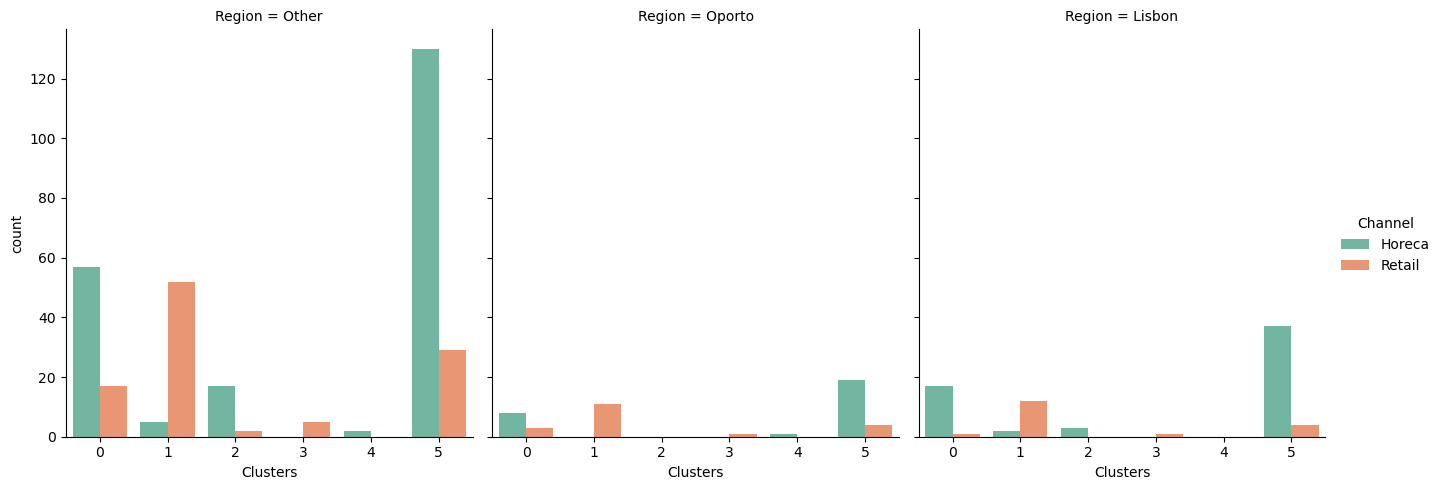

In [66]:
sns.catplot(
    data=df,
    x='Clusters',
    hue='Channel',
    col='Region',
    kind='count',
    palette='Set2',
    height=5,
    aspect=0.9
)

plt.show()

### Relação dos clusters com Channel e Region

Os clusters apresentam diferenças na sua composição por canal. Nos clusters 0, 2 e 5 predominam os clientes Horeca, com 82 de 103, 20 de 22 e 186 de 223 clientes, respetivamente. O cluster 4 é constituído pelos três clientes Horeca que o integram.

No cluster 1 predominam os clientes Retail, com 75 dos 82 clientes. O cluster 3 é composto exclusivamente por sete clientes Retail.

Estes resultados são consistentes com os perfis de compras identificados: os clusters 1 e 3 destacam-se em Grocery, Milk e Detergents_Paper, categorias cujas medianas são superiores no canal Retail na análise exploratória.

Relativamente à região, Other é a mais representada em todos os clusters. Contudo, esta região também reúne a maioria dos clientes do dataset, pelo que as contagens absolutas não permitem concluir, por si só, que existe uma associação particular entre Other e um determinado cluster.

A presença de clientes dos dois canais em vários grupos mostra que os clusters não reproduzem exatamente a divisão entre Horeca e Retail. Os grupos refletem os atributos utilizados pelo K-Means, incluindo a região, conforme a orientação do professor.

## 6. Conclusões

A análise do dataset Wholesale Customers permitiu identificar diferenças nos padrões de compras dos clientes e aplicar técnicas de classificação e clustering para explorar esses padrões.

Após o preenchimento dos valores omissos e a remoção de quatro registos duplicados, foram analisados 440 clientes. Os possíveis outliers foram mantidos, por poderem representar volumes de compras reais e relevantes para o negócio.

Na análise exploratória, Horeca apresentou medianas superiores em Fresh e Frozen, enquanto Retail se destacou em Milk, Grocery, Detergents_Paper e Delicassen. Foram também observadas diferenças entre regiões e uma correlação positiva muito forte entre Grocery
e Detergents_Paper. A análise por canal mostrou que a intensidade de algumas relações varia entre Horeca e Retail.

A árvore de decisão classificou corretamente 93 dos 110 clientes de teste, obtendo uma accuracy de aproximadamente 84,55%. O desempenho foi superior em Horeca, e Detergents_Paper apresentou a maior importância no modelo, seguido de Grocery e Milk. Estas métricas devem ser interpretadas tendo em conta a limitação do preenchimento dos valores omissos descrita na classificação.

O K-Means foi aplicado às seis categorias de compras e à região, conforme a orientação do professor. A solução com seis clusters
permitiu distinguir um grupo numeroso com compras relativamente baixas e grupos com compras elevadas em categorias específicas, como Fresh, Frozen ou Grocery, Milk e Detergents_Paper.

A comparação posterior com Channel revelou predominância de Retail nos clusters 1 e 3 e de Horeca nos restantes. Contudo, vários grupos
incluem clientes dos dois canais, mostrando que os segmentos encontrados não correspondem exatamente à classificação comercial.

As principais limitações incluem a preparação dos dados para a classificação, a codificação numérica da região no K-Means, a ausência de padronização das compras no clustering, a presença de valores extremos e a dimensão reduzida de alguns grupos. Os resultados dependem destas escolhas e não devem ser generalizados sem considerar essas limitações.

Como trabalho futuro, seria pertinente rever a preparação dos dados para os modelos, comparar diferentes números de clusters e avaliar outras configurações da árvore de decisão.

In [67]:
df.head()

,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Channel,Clusters
0,Other,1420,10810.0,16267.0,1593,6766,1838.0,Retail,1
1,Oporto,29635,2335.0,8280.0,3046,371,117.0,Horeca,0
2,Lisbon,8475,1931.0,1883.0,5004,3593,987.0,Horeca,5
3,Lisbon,11092,5008.0,5249.0,453,392,373.0,Horeca,5
4,Other,17623,4280.0,7305.0,2279,960,2616.0,Horeca,0


In [68]:
df.to_csv('./output/Dataset_F_Wholesale_Final.csv', index = False)